# Fisher forecasts with FIONA

This notebook walks through the Fisher-forecast part of the paper. It reproduces the LISA and LIGO forecasts for a cored isothermal sphere (CIS) lens.

1. Compute the lensing amplification factor $F(w, y)$ with FIONA.
2. See which part of $F$ each detector's sources probe.
3. Turn the Fisher covariances into marginalized uncertainties and confidence ellipses.

The covariances behind the paper's figures ship in `data/fisher_covariances.npz`, so the notebook runs in seconds and reproduces those figures exactly. To recompute the covariances with FIONA, run `python scripts/1_fisher/fisher_forecasts.py compute`.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='Wswiglal')   # silence a LALSuite notice in Jupyter

import finufft  # must be imported before FIONA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths, quadrature, table
from infer_with_fiona.fiona.axisym import FresnelNUFHTLensBatched
from infer_with_fiona.fisher import f_isco, f_1month
from infer_with_fiona.fisher.utils import G_over_c3_Msun

## 1. The amplification factor

A lens of redshifted mass $M_{Lz}$ multiplies the gravitational waveform by $F(w, y, x_c)$. Here
$$w = 8\pi \frac{G M_{Lz}}{c^3} f$$
is the dimensionless frequency, $y$ is the source position and $x_c$ is the CIS core radius, both in units of the Einstein radius.

FIONA evaluates $F$ for a whole set of source positions in one call. We use the converged Gauss-Legendre schedule (`cis`) and the paper's fiducial lens, $x_c = 0.01$.

In [2]:
quadrature.get_schedule('cis').apply()

XC = 0.01
w = np.logspace(-2, 2, 400)
y_values = np.array([0.3, 1.0, 3.0])

solver = FresnelNUFHTLensBatched([table.make_lens('CIS', XC)], gl_dir=str(paths.GL_RULES_DIR),
                                 n_workers=8, print_timing=False)
F = solver(w, y_values)[:, 0, :]          # shape (n_w, n_y): one call for all source positions
F.shape

(400, 3)

At low $w$ the wavelength is much larger than the lens, the wave diffracts around it, and $F \to 1$. At high $w$, $F$ approaches the geometric-optics sum over images, $F_{\rm GO} = \sum_j \sqrt{|\mu_j|}\, e^{i w T_j - i\pi n_j}$, whose interference produces the oscillations.

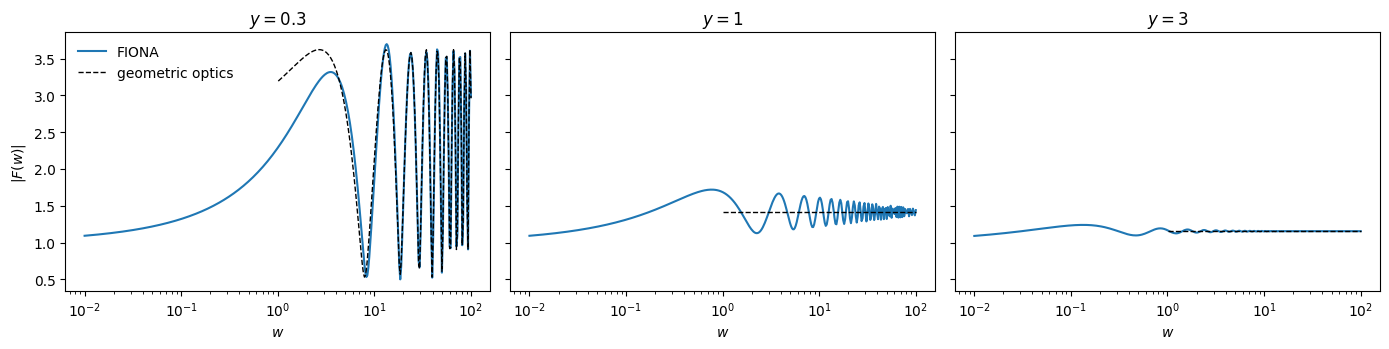

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, y, Fy in zip(axes, y_values, F.T):
    ax.semilogx(w, np.abs(Fy), color='tab:blue', lw=1.5, label='FIONA')
    w_go = w[w > 1]
    ax.semilogx(w_go, np.abs(table.F_go(w_go, *table.cis_image_set(XC, y))), 'k--', lw=1, label='geometric optics')
    ax.set(title=rf'$y = {y:g}$', xlabel='$w$')
axes[0].set_ylabel(r'$|F(w)|$')
axes[0].legend(frameon=False)
plt.tight_layout()

## 2. Which part of $F$ each detector sees

The forecasts use $y = 0.3$ and $x_c = 0.01$. A source contributes signal from the lowest frequency in band up to its innermost stable circular orbit, $f_{\rm ISCO}$. For LISA we keep the last month before merger, as in Tambalo et al. (2023).

Each source is paired with its own lens mass. Let $f_*$ be the frequency below which 90% of the source's unlensed SNR$^2$ accumulates. The lens mass is chosen so that $w(f_*) = 10$, which places the band across the wave-optics regime $w \sim 1$ and the onset of the interference fringes. The masses are stored with the covariances.

In [4]:
data = np.load(paths.FISHER_COVARIANCES)
Y_FID = 0.3
SOURCES = {  # detector: [(name, key, m1, m2)], source redshift, band [Hz]
    'LISA': ([('SMBHB 1e4+1e4', 'SMBHB_1e4', 1e4, 1e4), ('SMBHB 1e5+1e5', 'SMBHB_1e5', 1e5, 1e5),
              ('SMBHB 1e6+1e6', 'SMBHB_1e6', 1e6, 1e6)], 3.0, (1e-4, 1.0)),
    'LIGO': ([('BNS 1.4+1.4', 'BNS', 1.4, 1.4), ('NSBH 10+1.4', 'NSBH', 10, 1.4), ('BBH 10+10', 'BBH_10', 10, 10),
              ('BBH 30+30', 'BBH_30', 30, 30), ('BBH 60+60', 'BBH_60', 60, 60)], 0.1, (10.0, 1000.0)),
}
rows = []
for det, (srcs, z_s, (f_min, f_max)) in SOURCES.items():
    for name, key, m1, m2 in srcs:
        M, eta = m1 + m2, m1 * m2 / (m1 + m2) ** 2
        f_lo, f_hi = max(f_1month(M, eta, z_s), f_min), min(f_isco(M, z_s), f_max)
        M_Lz = float(data[f'{det}_{key}_mlz'])
        w_of = lambda f: 8 * np.pi * G_over_c3_Msun * M_Lz * f
        rows.append(dict(detector=det, source=name, f_star=float(data[f'{det}_{key}_fstar']), M_Lz=M_Lz,
                         w_min=w_of(f_lo), w_star=w_of(float(data[f'{det}_{key}_fstar'])), w_max=w_of(f_hi)))
bands = pd.DataFrame(rows)
bands.style.format({'f_star': '{:.3g}', 'M_Lz': '{:.2g}', 'w_min': '{:.2g}', 'w_star': '{:.2g}', 'w_max': '{:.2g}'}).hide(axis='index')

detector,source,f_star,M_Lz,w_min,w_star,w_max
LISA,SMBHB 1e4+1e4,0.0105,7.7e+06,0.81,10,52
LISA,SMBHB 1e5+1e5,0.00479,1.7e+07,0.42,10,11
LISA,SMBHB 1e6+1e6,0.000532,1.5e+08,1.9,10,10
LIGO,BNS 1.4+1.4,231,3.5e+02,0.43,10,43
LIGO,NSBH 10+1.4,168,4.8e+02,0.6,10,21
LIGO,BBH 10+10,139,5.8e+02,0.72,10,14
LIGO,BBH 30+30,61.6,1.3e+03,1.6,10,11
LIGO,BBH 60+60,32.5,2.5e+03,3.1,10,10


Every band now starts at $w \approx 0.4$ to $3$ and ends at $w \approx 10$ to $50$. If the lens were lighter, so that the band stayed at $w \lesssim 1$, most of the signal would accumulate where $F \approx 1$, the Fisher matrix would be nearly singular, and the lens parameters would be essentially unconstrained.

## 3. From Fisher matrix to constraints

For a signal $\tilde h_L(f; \boldsymbol\theta) = F(w, y, x_c)\,\tilde h_0(f)\,e^{i\varphi_0}$ in Gaussian noise with power spectral density $S_n(f)$, the Fisher matrix is
$$F_{ij} = 4\,\mathrm{Re}\int \frac{df}{S_n(f)}\,\frac{\partial \tilde h_L^*}{\partial\theta_i}\frac{\partial \tilde h_L}{\partial\theta_j},
\qquad \boldsymbol\theta = (\ln M_{Lz},\, y,\, x_c,\, \ln D_L,\, \varphi_0).$$
FIONA provides the derivatives of $F$ by central finite differences, batching $y \pm \varepsilon$ and $x_c \pm \varepsilon$ into the same call. Above the lens-dependent frequency $w_s(x_c, y)$ at which the beyond-geometric-optics sum agrees with FIONA to $10^{-3}$, `compute_F_and_derivatives` blends into that sum, with the same weight on $F$ and on every derivative. For $x_c = 0.01$, $y = 0.3$ the sum never reaches that accuracy below $w = 254$, so FIONA is used over the whole band. The distance and phase are marginalized over, which leaves a $3\times3$ covariance for $(\ln M_{Lz}, y, x_c)$.

One subtlety is the time reference of $F$. FIONA's $F$ carries the phase $e^{iw\phi_{\min}(y, x_c)}$ of the first-arriving image, a lens-dependent shift of the whole signal in time. An overall time shift is not a lensing observable, so, as in Tambalo et al. (2023), $F$ and its derivatives are multiplied by $e^{-iw\phi_{\min}}$, which measures arrival times from the first image.

The Fisher matrix scales as $\varrho^2$, the squared signal-to-noise ratio. So we quote every source at a common SNR, $\varrho_{\rm fid} = 10^3$ for LISA and $10^2$ for LIGO, by rescaling the covariance by $(\varrho/\varrho_{\rm fid})^2$.

In [5]:
SNR_FID = {'LISA': 1e3, 'LIGO': 1e2}


def covariance(det, key):
    # Covariance of (ln M_Lz, y, x_c) rescaled to the fiducial SNR of the detector.
    k = f'{det}_{key}'
    return data[f'{k}_cov'] * (float(data[f'{k}_snr']) / SNR_FID[det]) ** 2


rows = []
for det, (srcs, _, _) in SOURCES.items():
    for name, key, *_ in srcs:
        sigma = np.sqrt(np.diag(covariance(det, key)))
        rows.append({'detector': det, 'source': name, 'M_Lz': float(data[f'{det}_{key}_mlz']), 'SNR_fid': SNR_FID[det],
                     'σ(ln M_Lz)': sigma[0], 'σ(y)': sigma[1], 'σ(x_c)': sigma[2]})
pd.DataFrame(rows).style.format({'M_Lz': '{:.2g}', 'SNR_fid': '{:.0f}', 'σ(ln M_Lz)': '{:.2g}', 'σ(y)': '{:.2g}', 'σ(x_c)': '{:.2g}'}).hide(axis='index')

detector,source,M_Lz,SNR_fid,σ(ln M_Lz),σ(y),σ(x_c)
LISA,SMBHB 1e4+1e4,7.7e+06,1000,0.009,0.002,0.0029
LISA,SMBHB 1e5+1e5,1.7e+07,1000,0.014,0.0019,0.0064
LISA,SMBHB 1e6+1e6,1.5e+08,1000,0.014,0.0017,0.0069
LIGO,BNS 1.4+1.4,3.5e+02,100,0.09,0.02,0.029
LIGO,NSBH 10+1.4,4.8e+02,100,0.092,0.019,0.034
LIGO,BBH 10+10,5.8e+02,100,0.12,0.021,0.049
LIGO,BBH 30+30,1.3e+03,100,0.15,0.019,0.072
LIGO,BBH 60+60,2.5e+03,100,0.19,0.021,0.093


### Confidence ellipses

A Gaussian with covariance $C$ has its 68% and 95% contours at $\Delta\chi^2 = 2.30$ and $5.99$ in two dimensions. `infer_with_fiona.fisher.plotting.corner_fig` draws them for every parameter pair, with the 1D marginals on the diagonal. It is the function that made the paper's figures, and the files it saves below are identical to them.

In [6]:
from IPython.display import Image, display
from infer_with_fiona.fisher.plotting import corner_fig

COLORS = {'LISA': ['#4C72B0', '#DD8452', '#55A868'],
          'LIGO': ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']}
LEGEND = {'SMBHB 1e4+1e4': r'SMBHB ($10^4\,M_\odot+10^4\,M_\odot$)', 'SMBHB 1e5+1e5': r'SMBHB ($10^5\,M_\odot+10^5\,M_\odot$)',
          'SMBHB 1e6+1e6': r'SMBHB ($10^6\,M_\odot+10^6\,M_\odot$)', 'BNS 1.4+1.4': r'BNS ($1.4\,M_\odot+1.4\,M_\odot$)',
          'NSBH 10+1.4': r'NSBH ($10\,M_\odot+1.4\,M_\odot$)', 'BBH 10+10': r'BBH ($10\,M_\odot+10\,M_\odot$)',
          'BBH 30+30': r'BBH ($30\,M_\odot+30\,M_\odot$)', 'BBH 60+60': r'BBH ($60\,M_\odot+60\,M_\odot$)'}
paths.FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def mass_label(m):
    e = int(np.floor(np.log10(m)))
    return rf'$M_{{Lz}}={m / 10 ** e:.1f}\times10^{{{e}}}\,M_\odot$'


def fisher_figure(det):
    # Save the paper's figure for this detector to outputs/figures and show the saved file.
    srcs = SOURCES[det][0]
    fname = paths.FIGURES_DIR / f'fisher_{det.lower()}.png'
    labels = [f"{LEGEND[name]}, {mass_label(float(data[f'{det}_{key}_mlz']))}" for name, key, *_ in srcs]
    fig = corner_fig([covariance(det, key) for _, key, *_ in srcs], labels, COLORS[det], (Y_FID, XC), fname)
    plt.close(fig)
    display(Image(filename=str(fname), width=560))

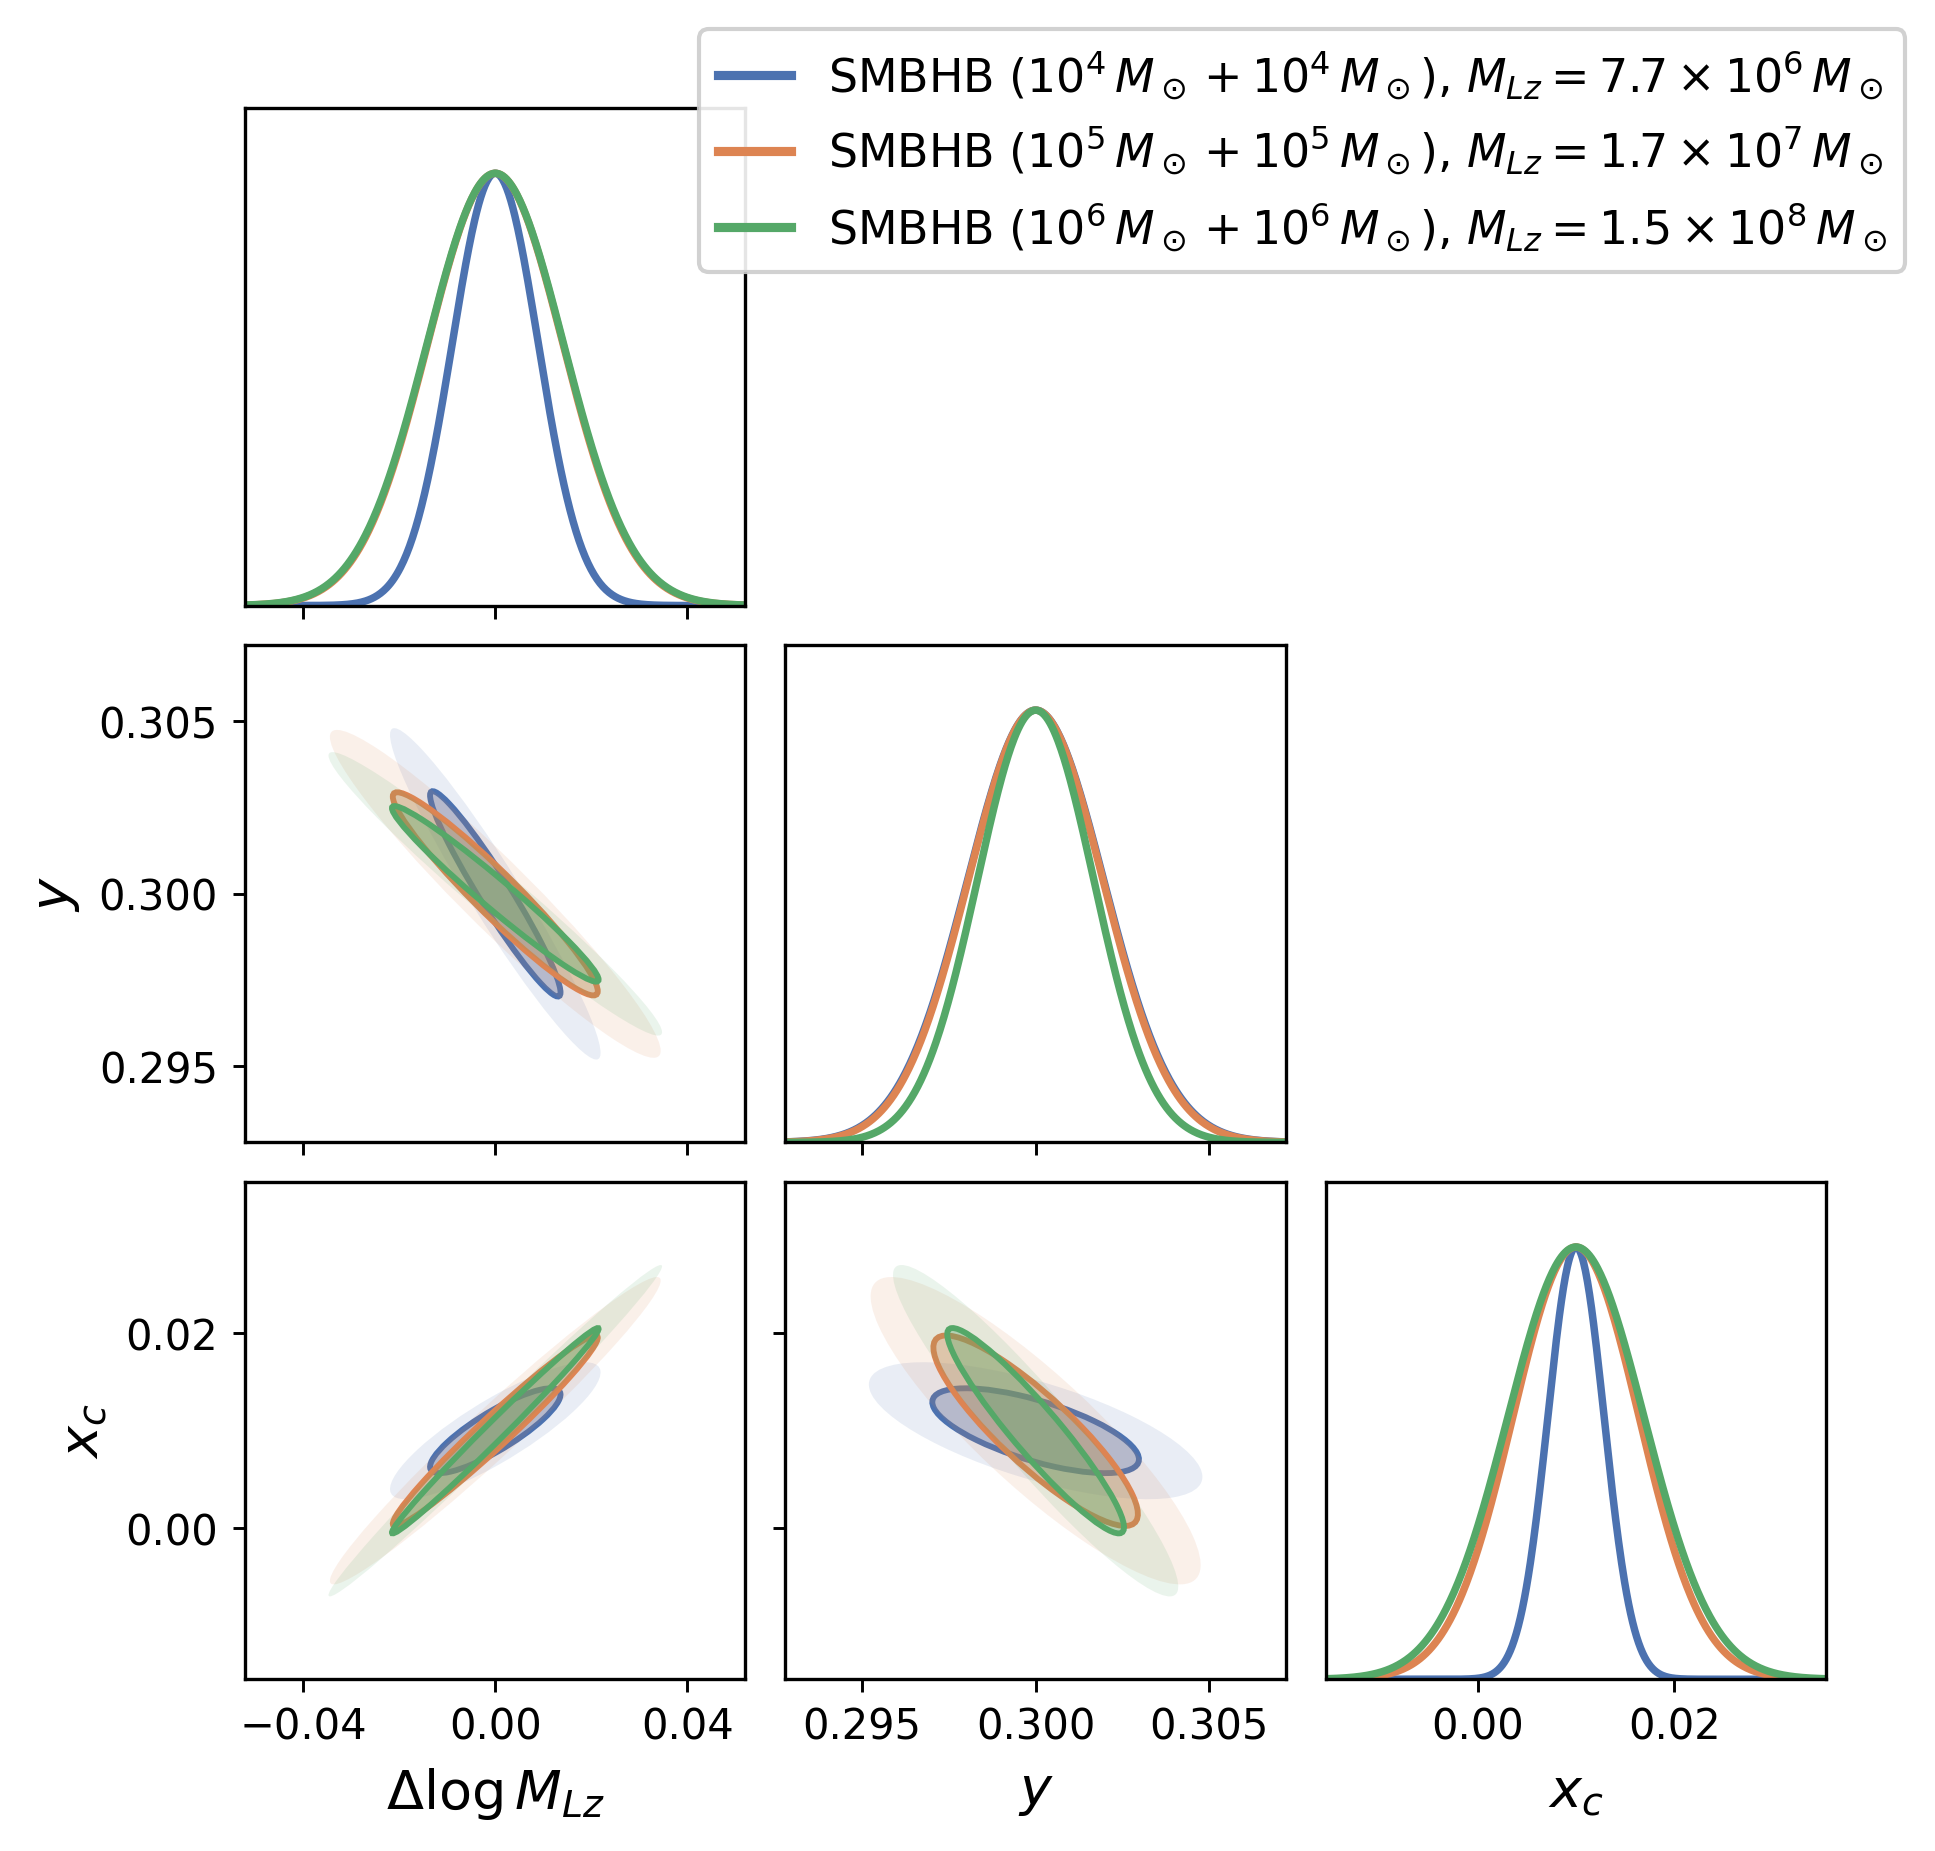

In [7]:
fisher_figure('LISA')     # the paper's LISA figure, rho = 1e3

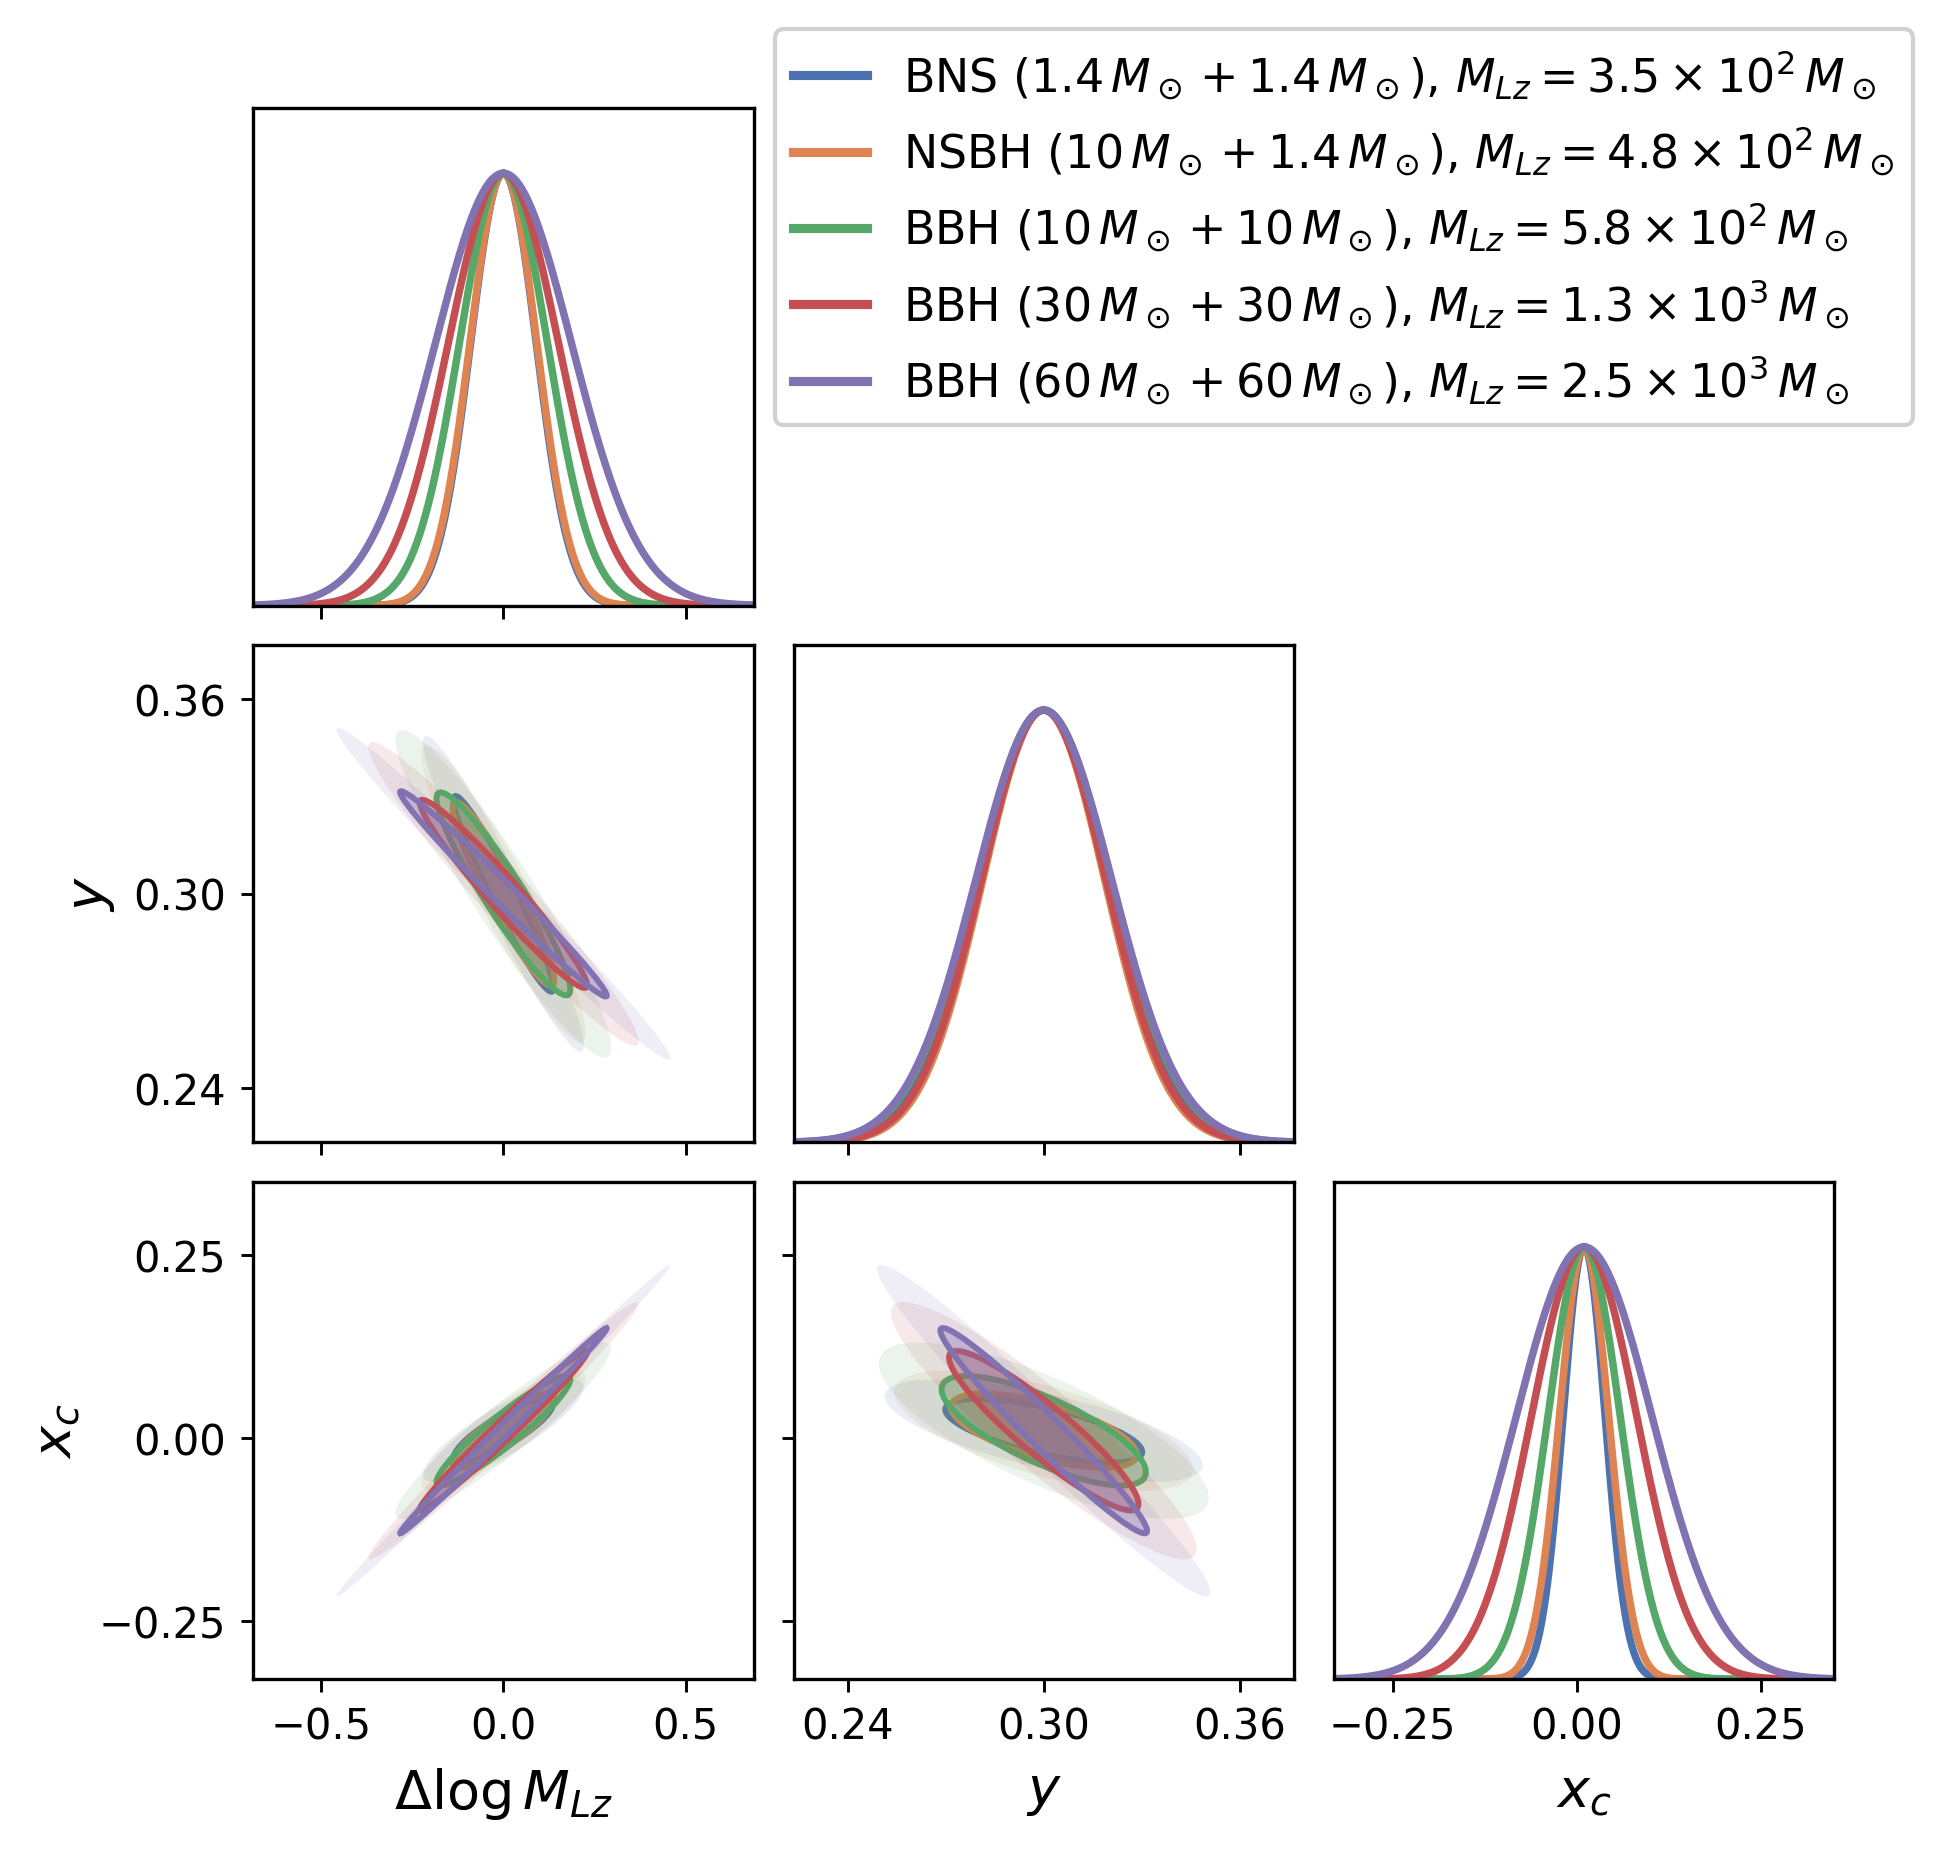

In [8]:
fisher_figure('LIGO')     # the paper's LIGO figure, rho = 1e2

## Summary

- **LISA.** At $\varrho = 10^3$, all three binaries determine $\ln M_{Lz}$ to 1 to 1.4% and $y$ to about 0.002. The lightest binary constrains the core best, $\sigma(x_c) \approx 0.003$, about half the value for the heavier two. Its band reaches $w \approx 50$, while the others end near $w \approx 10$, and the extra interference fringes break part of the degeneracy between $x_c$ and the other parameters.
- **LIGO.** At $\varrho = 10^2$, $\sigma(y) \approx 0.02$ for every source. $\sigma(\ln M_{Lz})$ grows from 0.09 (BNS) to 0.19 (60+60 BBH), and $\sigma(x_c)$ from 0.03 to 0.09, following the range of $w$ that each band covers.
- Scaled to the same SNR, the LIGO and LISA constraints are comparable, as expected since $F$ depends on the lens and source only through $w$, $y$ and $x_c$.